In [71]:

import os
import uuid
import hashlib
import platform
import numpy as np
import scipy
import matplotlib.pyplot as plt
import pandas as pd


STUDENT_ID = 20244080213
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "base")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")

# 设置全局随机种子，满足实验随机抽样固定种子要求
np.random.seed(42)


[Conda 环境] exp01_env
[学号] 20244080213
[机器指纹] d9743eb280c9a502
[RUN_ID] 20244080213-d9743eb280c9a502


In [72]:
# 创建三种数组
arr_int = np.array([1,2,3,4])
arr_float = np.array([1.1,2.2,3.3])
arr_bool = np.array([True, False, True])

print("整数数组：")
print(f"dtype={arr_int.dtype}, shape={arr_int.shape}, ndim={arr_int.ndim}")
print("浮点数数组：")
print(f"dtype={arr_float.dtype}, shape={arr_float.shape}, ndim={arr_float.ndim}")
print("布尔数组：")
print(f"dtype={arr_bool.dtype}, shape={arr_bool.shape}, ndim={arr_bool.ndim}")


整数数组：
dtype=int64, shape=(4,), ndim=1
浮点数数组：
dtype=float64, shape=(3,), ndim=1
布尔数组：
dtype=bool, shape=(3,), ndim=1


Markdown 解释：
numpy 数组所有元素必须是同一数据类型，存储连续内存，运算速度快；Python 列表元素可以是任意混合类型，内存分散，循环运算慢。

In [73]:
a = np.arange(12)
print("原始一维数组：", a)

a1 = a.reshape(3,4)
print("\nreshape(3,4):")
print(a1)

a2 = a.reshape(2,3,2)
print("\nreshape(2,3,2):")
print(a2)


原始一维数组： [ 0  1  2  3  4  5  6  7  8  9 10 11]

reshape(3,4):
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

reshape(2,3,2):
[[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]]


Markdown 解释：改变形状时，新 shape 所有维度乘积必须等于数组总元素个数，12 = 34 = 23*2

In [74]:
arr_34 = np.arange(12).reshape(3,4)
print("原始数组(3,4):\n", arr_34)

row2 = arr_34[1, :]   # 第2行，numpy从0开始索引
print("\n第2行：", row2, "shape:", row2.shape)

col1_3 = arr_34[:, 0:3] # 第1~3列
print("\n第1至3列：\n", col1_3, "shape:", col1_3.shape)

gt6 = arr_34[arr_34 > 6]
print("\n大于6的元素：", gt6, "shape:", gt6.shape)


原始数组(3,4):
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

第2行： [4 5 6 7] shape: (4,)

第1至3列：
 [[ 0  1  2]
 [ 4  5  6]
 [ 8  9 10]] shape: (3, 3)

大于6的元素： [ 7  8  9 10 11] shape: (5,)


In [75]:
ar = np.arange(10)
print("原数组", ar)

# 小于2 或 大于7
res_or = ar[(ar < 2) | (ar > 7)]
# res_or = ar[np.logical_or(ar<2, ar>7)]
print("小于2或大于7：", res_or)

#大于3并且小于7
res_and = ar[(ar>3) & (ar<7)]
# res_and = ar[np.logical_and(ar>3, ar<7)]
print("大于3且小于7：", res_and)


原数组 [0 1 2 3 4 5 6 7 8 9]
小于2或大于7： [0 1 8 9]
大于3且小于7： [4 5 6]


In [76]:
A = np.array([[1,2],[3,4]])
B = np.array([[5,6],[7,8]])

elem_star = A * B
elem_mult = np.multiply(A,B)
mat_at = A @ B
mat_matmul = np.matmul(A,B)

print("A*B逐元素乘法：\n", elem_star)
print("np.multiply逐元素乘法：\n", elem_mult)
print("@矩阵乘法：\n", mat_at)
print("np.matmul矩阵乘法：\n", mat_matmul)


A*B逐元素乘法：
 [[ 5 12]
 [21 32]]
np.multiply逐元素乘法：
 [[ 5 12]
 [21 32]]
@矩阵乘法：
 [[19 22]
 [43 50]]
np.matmul矩阵乘法：
 [[19 22]
 [43 50]]


 Markdown 解释:
 * / np.multiply(): 逐元素相乘，对应位置元素相乘;
@ / np.matmul(): 数学矩阵乘法，行乘列求和。


In [77]:
scores = np.random.normal(loc=70, scale=10, size=1000)
scores = np.clip(scores, 0, 100)

print(f"样本数:{len(scores)}")
print(f"最小值:{scores.min():.2f}")
print(f"最大值:{scores.max():.2f}")
print(f"均值:{scores.mean():.2f}")
print(f"标准差:{scores.std():.2f}")
print(f"极差:{scores.max()-scores.min():.2f}")


样本数:1000
最小值:37.59
最大值:100.00
均值:70.18
标准差:9.76
极差:62.41


In [78]:
pop = np.arange(1,11)
# 不放回均匀抽样
sample_uniform = np.random.choice(pop, size=5, replace=False)
print("均匀不放回抽样：", sample_uniform)

# 权重与整数大小成正比
p_weights = pop / pop.sum()
sample_weighted = np.random.choice(pop, size=5, replace=False, p=p_weights)
print("按大小比例加权抽样：", sample_weighted)


均匀不放回抽样： [ 4  9  2  6 10]
按大小比例加权抽样： [10  2  8  9  6]


In [79]:
ori = np.array([1,2,3,4,5])
arr1 = ori.copy()
arr2 = ori.copy()

# permutation 返回新数组，原数组不变
permuted = np.random.permutation(arr1)
print("permutation方式")
print("操作前原arr1:", arr1)
print("返回打乱新数组:", permuted)
print("操作后原arr1:", arr1)

# shuffle原地修改数组
print("\nshuffle原地打乱")
print("操作前arr2:", arr2)
np.random.shuffle(arr2)
print("操作后arr2:", arr2)


permutation方式
操作前原arr1: [1 2 3 4 5]
返回打乱新数组: [5 1 3 2 4]
操作后原arr1: [1 2 3 4 5]

shuffle原地打乱
操作前arr2: [1 2 3 4 5]
操作后arr2: [1 5 2 4 3]


In [80]:
score_nan = scores.copy()
#第10、20、30个值设为nan（索引9,19,29）
score_nan[[9,19,29]] = np.nan

mean_raw = np.mean(score_nan)
mean_nan_ign = np.nanmean(score_nan)
nan_count = np.sum(np.isnan(score_nan))

print(f"普通np.mean(含nan): {mean_raw}")
print(f"np.nanmean忽略缺失均值: {mean_nan_ign:.2f}")
print(f"缺失值数量：{nan_count}")


普通np.mean(含nan): nan
np.nanmean忽略缺失均值: 70.20
缺失值数量：3


Markdown 说明：数组存在np.nan时，普通np.mean结果直接得到nan；必须使用np.nanmean跳过缺失值计算

In [81]:
df_exp2 = pd.DataFrame({
    "index_no": np.arange(len(score_nan)),
    "score": score_nan
})
# 后续实验4直接使用df_exp2
print(df_exp2.head())


   index_no      score
0         0  74.967142
1         1  68.617357
2         2  76.476885
3         3  85.230299
4         4  67.658466


In [82]:
from scipy import linalg

M = np.array([[3, 1], [1, 2]])
b = np.array([9,8])
sol = linalg.solve(M, b)
print(f"方程组解 x={sol[0]}, y={sol[1]}")
#代入验证
verify = M @ sol
print("代入方程验证结果", verify)


方程组解 x=2.0, y=3.0
代入方程验证结果 [9. 8.]


In [83]:
from scipy.optimize import root

def f(x):
    return x**2 - 2

# 正根初猜2
res_pos = root(f, x0=2)
# 负根初猜‑2
res_neg = root(f, x0=-2)

print("求正根：")
print(f"成功？{res_pos.success}, 解={res_pos.x}, f(x)={res_pos.fun}")
print("求负根：")
print(f"成功？{res_neg.success}, 解={res_neg.x}, f(x)={res_neg.fun}")


求正根：
成功？True, 解=[1.41421356], f(x)=[8.8817842e-16]
求负根：
成功？True, 解=[-1.41421356], f(x)=[8.8817842e-16]


In [84]:
from scipy.optimize import minimize

def func(x):
    return x**2 + x + 2

res_min = minimize(func, x0=0)
print(f"极小点x={res_min.x}, 函数最小值={res_min.fun}")
#解析解 x=-0.5，f=1.75


极小点x=[-0.50000001], 函数最小值=1.75


In [85]:
from scipy.stats import ttest_ind

s1 = np.random.normal(loc=0, scale=1, size=100)
s2 = np.random.normal(loc=1, scale=1, size=100)

t_stat, p_val = ttest_ind(s1, s2)
print(f"t统计量={t_stat:.4f}, p值={p_val:.4f}")
alpha = 0.05
if p_val < alpha:
    print(f"p<0.05，拒绝原假设，两组均值存在显著差异")
else:
    print(f"p>=0.05，不能拒绝原假设，无充分证据说明均值不同")


t统计量=-6.2168, p值=0.0000
p<0.05，拒绝原假设，两组均值存在显著差异


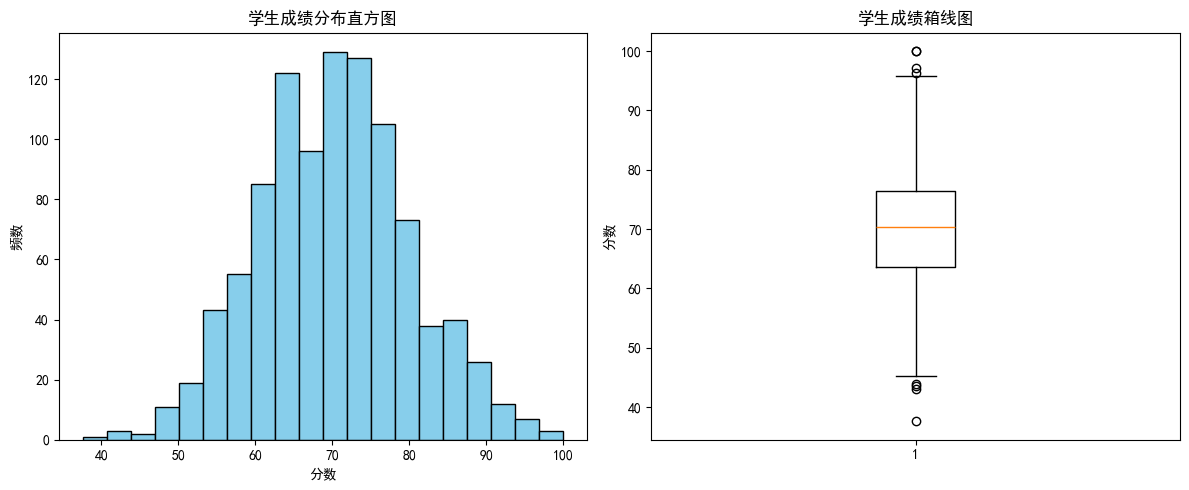

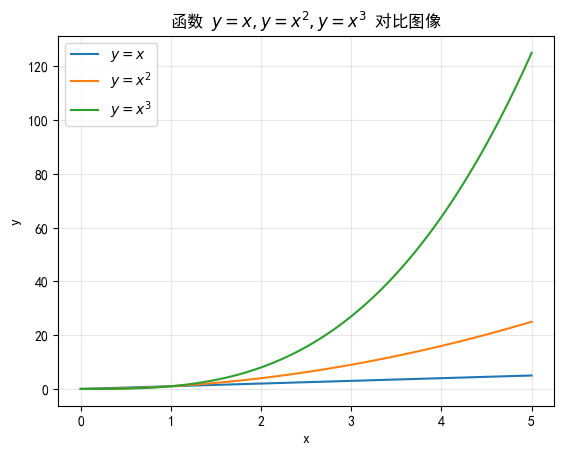

In [86]:
# 先放在最开头，解决中文方框问题
plt.rcParams['font.sans-serif'] = ['SimHei']  # 黑体
plt.rcParams['axes.unicode_minus'] = False    # 负号正常显示

# 过滤掉nan，用于绘图
valid_score = score_nan[~np.isnan(score_nan)]

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.hist(valid_score, bins=20, color="skyblue", edgecolor='black')
plt.title("学生成绩分布直方图")
plt.xlabel("分数")
plt.ylabel("频数")

plt.subplot(1,2,2)
plt.boxplot(valid_score)
plt.title("学生成绩箱线图")
plt.ylabel("分数")
plt.tight_layout()
plt.show()

# 函数图像 y=x, y=x^2, y=x^3 0<=x<=5
x = np.linspace(0, 5, 100)
y1 = x
y2 = x**2
y3 = x**3

plt.figure()
plt.plot(x, y1, label="$y=x$")
plt.plot(x, y2, label="$y=x^2$")
plt.plot(x, y3, label="$y=x^3$")
plt.title("函数 $y=x,y=x^2,y=x^3$ 对比图像")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [87]:
records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "A", "B"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82]
}
df = pd.DataFrame(records)
df = df.set_index("Name")

# 计算总分、平均分
df["Total"] = df["Math"] + df["English"] + df["Python"]
df["Average"] = df["Total"] / 3

print("行索引：", df.index.tolist())
print("列名：", df.columns.tolist())
print("\n前3行：")
print(df.head(3))
print("\n基本统计信息：")
print(df.describe())


行索引： ['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank']
列名： ['Group', 'Math', 'English', 'Python', 'Total', 'Average']

前3行：
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Bob       A    72       68      80    220  73.333333
Carol     B    91       85      89    265  88.333333

基本统计信息：
            Math    English     Python       Total    Average
count   6.000000   6.000000   6.000000    6.000000   6.000000
mean   79.833333  80.833333  83.666667  244.333333  81.444444
std     9.907909   9.662643   8.547904   25.781130   8.593710
min    65.000000  68.000000  70.000000  208.000000  69.333333
25%    73.750000  74.000000  80.500000  225.750000  75.250000
50%    81.500000  81.000000  84.000000  250.000000  83.333333
75%    87.000000  88.750000  88.250000  263.000000  87.666667
max    91.000000  92.000000  95.000000  273.000000  91.000000


In [88]:
# loc按标签
carol_loc = df.loc["Carol"]
print("loc读取Carol\n", carol_loc)

# iloc按位置，Carol是第2行(index从0)
carol_iloc = df.iloc[2]
print("\niloc读取Carol\n", carol_iloc)

high_avg = df[df["Average"] >=80]
print("\n平均分>=80学生：")
print(high_avg)


loc读取Carol
 Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object

iloc读取Carol
 Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object

平均分>=80学生：
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Carol     B    91       85      89    265  88.333333
Eva       A    79       92      86    257  85.666667
Frank     B    84       77      82    243  81.000000


In [89]:
col_mean = df[["Math","English","Python"]].mean(axis=0)
print("各科列均值(axis=0):\n", col_mean)

row_mean = df[["Math","English","Python"]].mean(axis=1)
print("\n每个学生行均值(axis=1):\n", row_mean)


各科列均值(axis=0):
 Math       79.833333
English    80.833333
Python     83.666667
dtype: float64

每个学生行均值(axis=1):
 Name
Alice    91.000000
Bob      73.333333
Carol    88.333333
David    69.333333
Eva      85.666667
Frank    81.000000
dtype: float64


In [90]:
# apply每行最高分
df["max_subject"] = df[["Math","English","Python"]].apply(max, axis=1)
print("每行最高分：\n", df["max_subject"])

# agg一次性多统计
stat_agg = df[["Math","English","Python"]].agg(["min","mean","max"])
print("\nagg统计每科min mean max\n", stat_agg)

# rank按Total排名
df["rank_total"] = df["Total"].rank(ascending=False)
print("\n按总分排名：")
print(df[["Total","rank_total"]])


每行最高分：
 Name
Alice    95
Bob      80
Carol    91
David    73
Eva      92
Frank    84
Name: max_subject, dtype: int64

agg统计每科min mean max
            Math    English     Python
min   65.000000  68.000000  70.000000
mean  79.833333  80.833333  83.666667
max   91.000000  92.000000  95.000000

按总分排名：
       Total  rank_total
Name                    
Alice    273         1.0
Bob      220         5.0
Carol    265         2.0
David    208         6.0
Eva      257         3.0
Frank    243         4.0


In [91]:
group_stat = df.groupby("Group").agg(人数=("Math","count"), 三科平均分=("Average","mean"))
print("分组统计：")
print(group_stat)

# transform，每行增加本组Python平均分
df["group_python_mean"] = df.groupby("Group")["Python"].transform("mean")
print("\n带组Python平均分的df：")
print(df[["Group","Python","group_python_mean"]])


分组统计：
       人数      三科平均分
Group               
A       3  83.333333
B       3  79.555556

带组Python平均分的df：
      Group  Python  group_python_mean
Name                                  
Alice     A      95          87.000000
Bob       A      80          87.000000
Carol     B      89          80.333333
David     B      70          80.333333
Eva       A      86          87.000000
Frank     B      82          80.333333


In [92]:
def filter_func(g):
    return g["Python"].mean() >= 80

df_filtered = df.groupby("Group").filter(filter_func)
print("Python组平均分>=80的组与学生：")
print(df_filtered)


Python组平均分>=80的组与学生：
      Group  Math  English  Python  Total    Average  max_subject  rank_total  \
Name                                                                            
Alice     A    88       90      95    273  91.000000           95         1.0   
Bob       A    72       68      80    220  73.333333           80         5.0   
Carol     B    91       85      89    265  88.333333           91         2.0   
David     B    65       73      70    208  69.333333           73         6.0   
Eva       A    79       92      86    257  85.666667           92         3.0   
Frank     B    84       77      82    243  81.000000           84         4.0   

       group_python_mean  
Name                      
Alice          87.000000  
Bob            87.000000  
Carol          80.333333  
David          80.333333  
Eva            87.000000  
Frank          80.333333  


In [93]:
score_cols = ["Math","English","Python"]
cov_mat = df[score_cols].cov()
corr_mat = df[score_cols].corr()

print("协方差矩阵：\n", cov_mat)
print("\n相关系数矩阵：\n", corr_mat)


协方差矩阵：
               Math    English     Python
Math     98.166667  62.566667  74.933333
English  62.566667  93.366667  62.533333
Python   74.933333  62.533333  73.066667

相关系数矩阵：
              Math   English    Python
Math     1.000000  0.653529  0.884776
English  0.653529  1.000000  0.757105
Python   0.884776  0.757105  1.000000
